In [65]:
from datetime import date, timedelta

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

import polars as pl
import polars.selectors as cs

In [2]:
import alleg.process_data as data
import alleg.report as report

Question: How many devices will need to be inspected within the next month?

Assumptions:

- If the device is deleted or the store is out of business, it will not be inspected. Same if the store_id does not exist.
- Take the inspection_cycle column at face value (12, 36, or 60 month; a handful of OTHER and null values shall be skipped).
- This does not include the 2,166 devices which have no inspections recorded but are marked as active.
- Nor the ~8,000 devices which should have been reinspected already some time ago.

In [82]:
(Inspections := data.Inspections.collect())

_id,inspection_id,store_id,device_id,date,result,reinspection
i64,i64,i64,i64,date,cat,cat
89532961,38362,30460,5445,2016-05-03,"""Pass""","""No"""
89532962,47971,31879,9013,2016-01-07,"""Pass""","""No"""
89532963,47972,30416,6893,2016-01-07,"""Pass""","""Yes"""
89532964,47973,31699,8346,2016-01-07,"""Pass""","""Yes"""
89532965,47974,32341,14011,2016-01-07,"""Pass""","""No"""
…,…,…,…,…,…,…
89743843,259931,30561,39809,2026-10-22,"""Pass""","""Yes"""
89743844,259932,30561,39809,2026-10-22,"""Fail""","""Yes"""
89743845,259933,31860,21897,2026-10-22,"""Fail""","""Yes"""


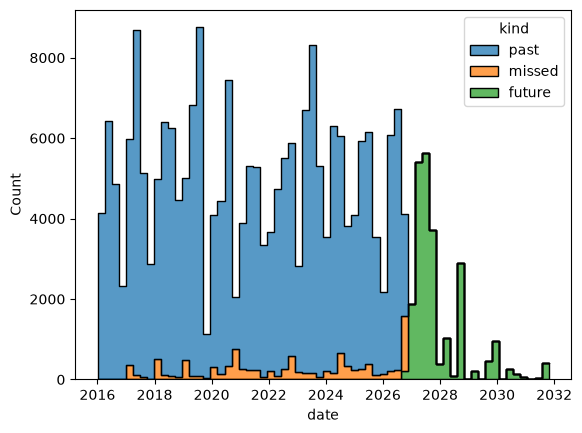

In [111]:
# Date histogram of:
# 1) Inspections that happened
# 2) Computed upcoming inspections in the past (i.e. didn't happen as of today)
# 3) Computed upcoming inspections in the future
sns.histplot(
    pl.concat([
        data.Inspections.select(
            pl.col('date'),
            pl.lit('past').alias('kind'),
        ),
        UpcomingReinspections.select(
            pl.col('date'),
            pl.when(
                pl.col('date') < date.today(),
            ).then(pl.lit('missed').alias('kind')).otherwise(pl.lit('future')),
        ),
    ]).collect().to_dict(),
    x='date',
    hue='kind',
    multiple='stack',
    bins=64,  # three-month buckets given the current extent of data
    element='step',
);

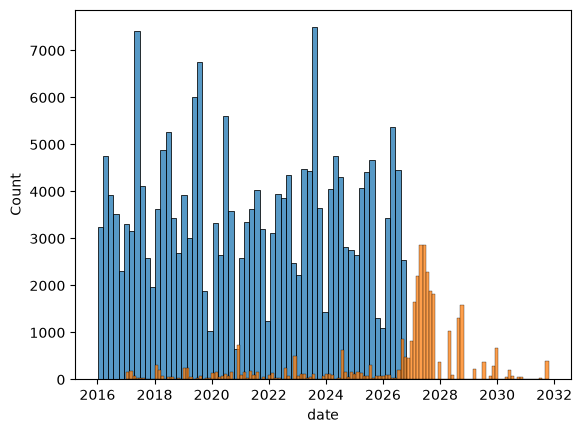

In [87]:
ax=sns.histplot(
    Inspections.to_dict(),
    x='date',
);
sns.histplot(
    UpcomingReinspections.collect().to_dict(),
    x='date',
    ax=ax,
);

In [16]:
LatestInspections = data.Inspections.sort('date').group_by('device_id', maintain_order=True).last()

In [23]:
UpcomingReinspections = LatestInspections.join(
    data.Devices.select('device_id', 'offset'), 'device_id',
).select(
    'device_id',
    'store_id',
    pl.col('date').dt.offset_by(pl.col('offset')),
)

In [52]:
UpcomingReinspections.group_by(
    'store_id',
    pl.col('date').dt.truncate('1mo'),
).agg().collect()

store_id,date
i64,date
33113,2027-07-01
31723,2027-05-01
31919,2020-06-01
31842,2019-09-01
33159,2024-09-01
…,…
41087,2026-11-01
32291,2024-03-01
30894,2026-03-01


In [79]:
UpcomingReinspections.filter(
    pl.col('date').is_between(
        date.today(),
        date.today() + timedelta(days=7),
    )
).group_by(
    'store_id',
).agg(
    pl.count('device_id').alias('device_count'),
).join(data.Stores.select('store_id', 'store_name', 'address'), 'store_id').collect()

store_id,device_count,store_name,address
i64,u64,str,str
31355,2,"""AMTRAK""","""1100 LIBERTY AVE"""
32563,2,"""BOOK COUNTRY""","""3200 WALNUT ST"""
32940,2,"""UPMC EAST CAFETERIA""","""2775 MOSSIDE"""
40147,1,"""UHAUL (PROPANE)""","""5 CLAIRTON BLVD"""
40529,1,"""DYLAMATOS MARKET""","""5414 2ND AVE"""
…,…,…,…
40823,1,"""MERCURIO'S""","""1335 FREEPORT RD"""
40460,1,"""MERCURIOS""","""5523 WALNUT ST"""
40551,1,"""CHANTALS CHEESE SHOP""","""4402 PENN AVE"""


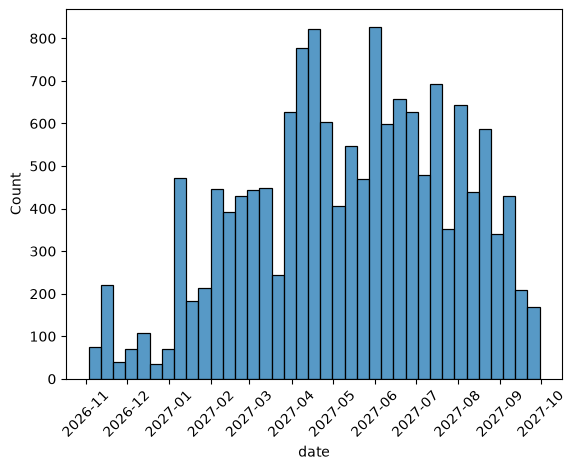

In [64]:
sns.histplot(
    UpcomingReinspections.filter(
        pl.col('date')>date.today(),
        pl.col('date')<date(2027,10,1),
    ).collect().to_dict(),
    x='date',
)
plt.gca().xaxis.set_tick_params(rotation=45)

In [46]:
UpcomingReinspections.group_by().len().show()

len
u64
34232


<Axes: xlabel='date'>

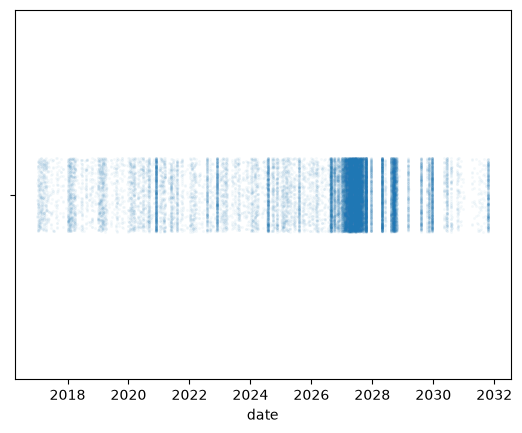

In [38]:
sns.stripplot(
    UpcomingReinspections.collect().to_dict(),
    x='date',
    alpha=0.05,
    s=2,
)

In [39]:
UpcomingReinspections.group_by(pl.col('date') < date(2026,8,1)).len().show()

date,len
bool,u64
false,25324
true,8908


In [9]:
data.Devices.filter(pl.col('inspection_cycle').is_null()).show()

_id,device_id,store_id,device_type,device_group,make,model,serial_number,pump,grade,capacity,inspection_cycle,remarks,deleted,offset
i64,i64,i64,str,cat,str,str,str,str,str,str,str,str,bool,str
11556755,10094,33129,"""AIR/VACUUM HOSE""","""TIMING""",null,null,null,null,null,null,null,null,false,null
11559742,13106,30313,"""DIGITAL""","""SCALE""","""HOBART""",null,"""1001932""",null,null,"""30 LB""",null,null,false,null


In [5]:
data.Devices.group_by('inspection_cycle').len().show()

inspection_cycle,len
str,u64
"""12 MONTH""",23784
"""36 MONTH""",3546
"""60 MONTH""",11969
"""OTHER""",1
null,2
